# Assignment 2, Tasks 1-2: Brain MRI Dataset

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 2

**Objective:** obtain the Brain Tumor Classification (MRI) dataset (Bhuvaji et al., 2020), place it where the provided `scripts/05_lrp.py` (deepfindr, 2021) expects it, and check it before modelling.

**Approach:** index every file once (split, class, size, content hash), find copies, near-copies and CT scans, then fix the training, validation and test subsets used by notebooks [05](05_vgg16_training.ipynb), [06](06_lrp.ipynb) and [07](07_gradcam.ipynb).

**Contents**
1. [Setup](#sec-setup)
2. [Task 1: download](#sec-download)
3. [Task 2: folder layout](#sec-layout)
4. [Class balance](#sec-balance)
5. [Image size and brightness](#sec-sizes)
6. [Duplicates and near-copies](#sec-duplicates)
7. [Sample images](#sec-samples)
8. [CT scans](#sec-ct)
9. [Modelling subsets](#sec-subsets)
10. [Key takeaways](#sec-takeaways)
11. [References](#sec-references)

<a id="sec-setup"></a>

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from scipy.stats import mannwhitneyu
from sklearn.linear_model import LogisticRegression
from torchvision.datasets import ImageFolder

from brain_mri_xai import SEED
from brain_mri_xai.data import (
    CLASS_LABELS,
    CLASSES,
    MANUAL_LABELS_PATH,
    MRI_DIR,
    NEAR_IDENTICAL_CORRELATION,
    RELATED_CORRELATION,
    compare_with_archive,
    download_archive,
    extract_archive,
    find_similar_pairs,
    flag_duplicates,
    grey_images,
    index_images,
    load_images,
    normalise,
    split_train_validation,
    standardise,
)
from brain_mri_xai.model import imagenet_features
from brain_mri_xai.plotting import CLASS_COLORS, show_image
from stroke_shap.plotting import FIGURE_WIDTH, label_panels, save_figure, set_theme

set_theme()

<a id="sec-download"></a>

## 2. Task 1: download

- **Source:** [SartajBhuvaji/Brain-Tumor-Classification-DataSet](https://github.com/SartajBhuvaji/Brain-Tumor-Classification-DataSet) (Bhuvaji et al., 2020), pinned to its only commit, `3ea9f4e`, so the files cannot change. First downloaded on 2 November 2026.
- **Download:** `download_archive()` saves the repository zip to the gitignored `data/` folder; `extract_archive()` unpacks it into `data/brain_mri/` on a first run.
- **Verification:** `compare_with_archive()` matches the SHA-256 hash of every image in the zip with its local copy. Files are compared one by one, because GitHub does not guarantee a byte-identical zip on each download.

In [2]:
if not MRI_DIR.exists():  # first run: install the pinned GitHub copy
    extract_archive(download_archive())
check = compare_with_archive(download_archive())
assert check["identical"].all(), "local images differ from the GitHub copy"
index = index_images()

comparison = (
    check.groupby("split")[["in_archive", "in_local", "identical"]].sum().loc[["training", "testing"]]
)
comparison.loc["Total"] = comparison.sum()
comparison.rename_axis("Split").rename(
    columns={
        "in_archive": "Files on GitHub",
        "in_local": "Files stored locally",
        "identical": "Identical (SHA-256)",
    }
)

,Files on GitHub,Files stored locally,Identical (SHA-256)
Split,,,
training,2870,2870,2870
testing,394,394,394
Total,3264,3264,3264


<a id="sec-layout"></a>

## 3. Task 2: folder layout

The images are placed in the layout `05_lrp.py` reads:

```
xai-series/
├── scripts/05_lrp.py
└── data/brain_mri/
    ├── training/   glioma_tumor 826 | meningioma_tumor 822 | no_tumor 395 | pituitary_tumor 827
    └── testing/    glioma_tumor 100 | meningioma_tumor 115 | no_tumor 105 | pituitary_tumor  74
```

- `05_lrp.py` loads each folder with `torchvision.datasets.ImageFolder`, which takes the class from the sub-folder name.
- Checked below: the counts match the tree, both folders give the four classes in the same order, and the data cells of `05_lrp.py` (imports, loading, preprocessing, data loaders) run unchanged and return a batch.
- **Output below:** the first `True` is the script's own GPU check (`print(torch.cuda.is_available())`); then the script's `TRAIN_ROOT` and `TEST_ROOT`, the image count of each folder and the class-to-index mapping that `ImageFolder` derives from the folder names.

In [3]:
expected = {
    "training": {"glioma_tumor": 826, "meningioma_tumor": 822, "no_tumor": 395, "pituitary_tumor": 827},
    "testing": {"glioma_tumor": 100, "meningioma_tumor": 115, "no_tumor": 105, "pituitary_tumor": 74},
}
for split, counts in expected.items():
    assert index[index["split"] == split].groupby("label").size().to_dict() == counts
    assert ImageFolder(MRI_DIR / split).class_to_idx == {label: i for i, label in enumerate(CLASSES)}

SCRIPTS = Path.cwd().parent / "scripts"
sys.path.insert(0, str(SCRIPTS))  # 05_lrp.py imports DATA_DIR from scripts/utils.py
blocks = (SCRIPTS / "05_lrp.py").read_text(encoding="utf-8").split("# %% ")[1:]
script_cells = dict(block.split("\n", 1) for block in blocks)  # cell title -> cell code
script = {}
for name in ["Imports", "Load data", "Prepare data for pretrained model", "Create data loaders"]:
    exec(script_cells[name], script)  # the provided cells, unchanged

for split, folder in [("train", "training"), ("test", "testing")]:
    assert len(script[f"{split}_dataset"]) == sum(expected[folder].values())
    images, _ = next(iter(script[f"{split}_loader"]))
    assert images.shape[0] == script[f"{split}_loader"].batch_size

project = Path.cwd().parent
for name, split in [("TRAIN_ROOT", "train"), ("TEST_ROOT", "test")]:
    root, dataset = script[name], script[f"{split}_dataset"]
    print(f"{name:<10} = {root.relative_to(project).as_posix():<24} {len(dataset):>4} images")
for split in ["train", "test"]:
    print(f"{split}_dataset.class_to_idx = {script[f'{split}_dataset'].class_to_idx}")
print(
    "Same class mapping in both folders:",
    script["train_dataset"].class_to_idx == script["test_dataset"].class_to_idx,
)

True


TRAIN_ROOT = data/brain_mri/training  2870 images
TEST_ROOT  = data/brain_mri/testing    394 images
train_dataset.class_to_idx = {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
test_dataset.class_to_idx = {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Same class mapping in both folders: True


<a id="sec-balance"></a>

## 4. Class balance

- **Training:** the three tumour classes are about equal (822-827 images); No Tumour has about half as many (395).
- **Testing:** the class proportions differ from training; pituitary is the smallest class (74).
- **Implication:** overall accuracy alone can hide a weak class, so [notebook 05](05_vgg16_training.ipynb#sec-performance) reports recall per class.

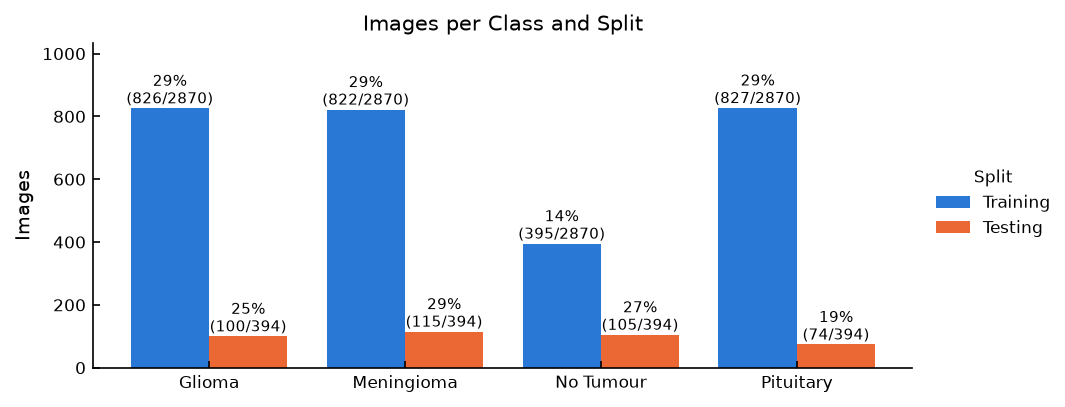

In [4]:
counts = index.groupby(["split", "label"]).size().unstack("split")[["training", "testing"]]
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 2.6))
x = np.arange(len(CLASSES))
for offset, split, color in [(-0.2, "training", "#2a78d6"), (0.2, "testing", "#eb6834")]:
    bars = ax.bar(x + offset, counts[split], width=0.4, color=color, label=split.title())
    labels = [
        f"{s:.0%}\n({n}/{counts[split].sum()})" for n, s in zip(counts[split], shares[split], strict=True)
    ]
    ax.bar_label(bars, labels=labels, fontsize=7)
ax.set_xticks(x, [CLASS_LABELS[c] for c in CLASSES])
ax.set_ylabel("Images")
ax.set_ylim(0, counts.values.max() * 1.25)
ax.set_title("Images per Class and Split")
fig.legend(loc="outside right center", title="Split")
save_figure(fig, "04_class_balance")

<a id="sec-sizes"></a>

## 5. Image size and brightness

- **Size, training:** 83-100% of tumour images are 512 x 512; almost no No Tumour images are.
- **Size, testing:** at most 19% of tumour images are 512 x 512.
- **Brightness** (mean grey level per image): in training, tumour images are darker than No Tumour images; in testing, tumour images are as bright as No Tumour images or brighter.
- **Brightness test:** per class, training and testing are compared with a two-sided Mann-Whitney U test (Mann & Whitney, 1947), Bonferroni-corrected for 4 tests, with the rank-biserial r as effect size (Kerby, 2014; positive = testing brighter, 1 = no overlap); results are under each class in the figure. Test images are brighter for all three tumour classes, with large effects (r = +0.52 to +0.73, corrected p < 0.001); No Tumour shows no clear difference (r = -0.10, corrected p = 0.45).
- **Why it matters:** every image is resized for the model, which hides the size itself but can leave traces (sharpness, stretched aspect ratio, border width), and overall brightness is visible to the model directly. A model that learns "not 512 x 512" or "bright" means No Tumour from training would call many test tumours No Tumour.
- **Implication:** the test results in [notebook 05](05_vgg16_training.ipynb#sec-performance) and the heatmaps are read with these shifts in mind.

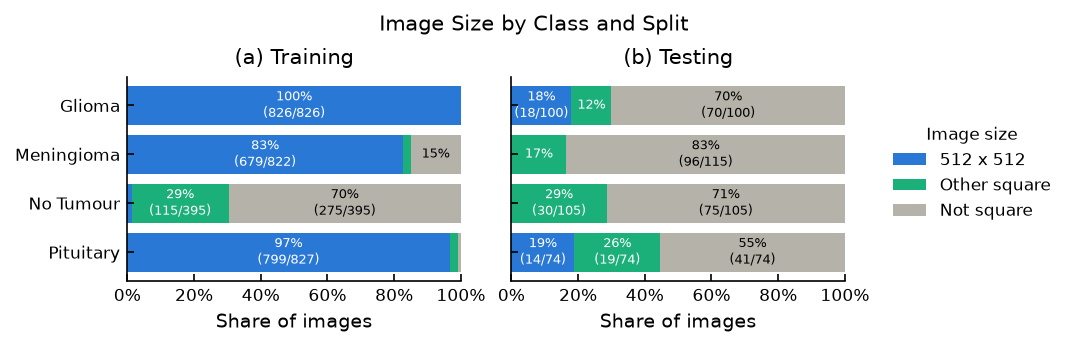

In [5]:
index["size"] = np.where(
    (index["width"] == 512) & (index["height"] == 512),
    "512 x 512",
    np.where(index["width"] == index["height"], "Other square", "Not square"),
)
size_counts = pd.crosstab([index["split"], index["label"]], index["size"])
size_shares = size_counts.div(size_counts.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.2), sharey=True)
for ax, split in zip(axes, ["training", "testing"], strict=True):
    data = size_shares.loc[split].reindex(CLASSES[::-1])
    n = size_counts.loc[split].reindex(CLASSES[::-1])
    left = np.zeros(len(data))
    for size, color, text in [
        ("512 x 512", "#2a78d6", "white"),
        ("Other square", "#1baf7a", "white"),
        ("Not square", "#b4b2a9", "black"),
    ]:
        bars = ax.barh([CLASS_LABELS[c] for c in data.index], data[size], left=left, color=color, label=size)
        labels = [
            f"{s:.0%}\n({k}/{total})" if s >= 0.17 else f"{s:.0%}" if s >= 0.08 else ""
            for s, k, total in zip(data[size], n[size], n.sum(axis=1), strict=True)
        ]
        ax.bar_label(bars, labels=labels, label_type="center", fontsize=6, color=text)
        left += data[size].to_numpy()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Share of images")
    ax.set_title(split.title())
label_panels(axes)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center", title="Image size")
fig.suptitle("Image Size by Class and Split")
save_figure(fig, "04_sizes")

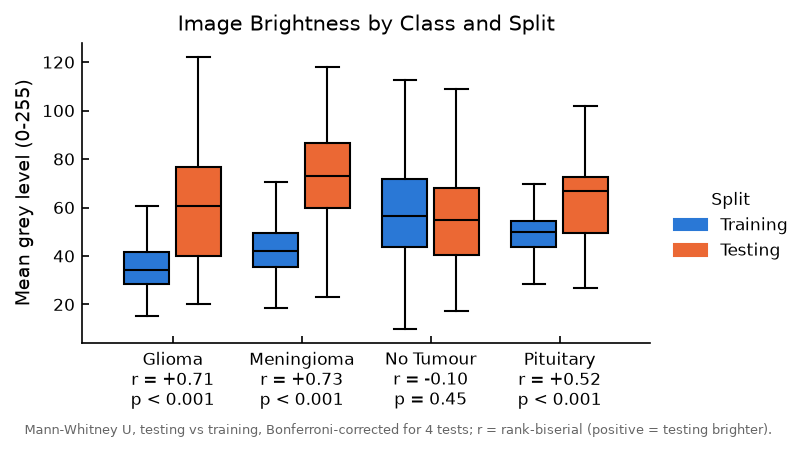

In [6]:
small = grey_images(index["path"], 128)  # grey scale, 128 x 128, reused below
index["brightness"] = small.mean(axis=(1, 2))

tick_labels = []
for label in CLASSES:  # Mann-Whitney U, testing vs training, Bonferroni-corrected for 4 tests
    train_values = index.loc[(index["split"] == "training") & (index["label"] == label), "brightness"]
    test_values = index.loc[(index["split"] == "testing") & (index["label"] == label), "brightness"]
    u, p = mannwhitneyu(test_values, train_values, alternative="two-sided")
    p = min(p * len(CLASSES), 1.0)
    r = 2 * u / (len(test_values) * len(train_values)) - 1  # rank-biserial
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.2f}"
    tick_labels.append(f"{CLASS_LABELS[label]}" + chr(10) + f"r = {r:+.2f}" + chr(10) + p_text)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 2.9))
for offset, split, color in [(-0.2, "training", "#2a78d6"), (0.2, "testing", "#eb6834")]:
    groups = [index.loc[(index["split"] == split) & (index["label"] == c), "brightness"] for c in CLASSES]
    boxes = ax.boxplot(
        groups,
        positions=np.arange(len(CLASSES)) + offset,
        widths=0.35,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black"},
    )
    for box in boxes["boxes"]:
        box.set_facecolor(color)
ax.set_xticks(np.arange(len(CLASSES)), tick_labels)
ax.set_ylabel("Mean grey level (0-255)")
ax.set_title("Image Brightness by Class and Split")
fig.legend(
    handles=[Patch(color="#2a78d6", label="Training"), Patch(color="#eb6834", label="Testing")],
    loc="outside right center",
    title="Split",
)
fig.supxlabel(
    "Mann-Whitney U, testing vs training, Bonferroni-corrected for 4 tests; "
    "r = rank-biserial (positive = testing brighter).",
    x=0.02,
    ha="left",
    fontsize=6,
    color="0.4",
)
save_figure(fig, "04_brightness")

<a id="sec-duplicates"></a>

## 6. Duplicates and near-copies

**Definitions** (correlation = pixel correlation of two grey-scale images at 256 x 256):

| Term | Meaning |
|---|---|
| Exact copy | Byte-identical file (same MD5 hash, confirmed byte by byte) |
| Near-identical | The same slice saved again (resized or recompressed): correlation of at least `NEAR_IDENTICAL_CORRELATION = 0.97`; includes exact copies |
| Related | Correlation of at least `RELATED_CORRELATION = 0.90`: near-identical images plus, mostly, neighbouring slices of the same scan series |

Images linked through a chain of pairs form one group (near-identical group, related group). The two thresholds were set by the author, who is not a radiologist, by inspecting all 102 candidate pairs between 0.95 and 0.995 and samples below 0.95 (examples in the second figure). Below 0.90 most pairs are different scans.

**Method** (`find_similar_pairs()`)

1. **Shortlist:** pairs whose 64-bit difference hashes agree in at least 52 of 64 bits (`max_hash_distance=12`), also with one image mirrored.
2. **Coarse check:** keep pairs with a correlation of at least `min_coarse_correlation=0.85` at 128 x 128.
3. **Final correlation** at 256 x 256.
4. **Shortlist check:** for 300 random images, every pair with a correlation of at least 0.95 found by comparing with all images is in the shortlist (asserted in the code).

**Rules** (`flag_duplicates()`)

- Drop a training image related to any test image.
- Within training, keep one image per near-identical group and drop the others.
- Keep related training images in the same subset ([Section 9](#sec-subsets)).
- Keep the test set as published; disclose its repeats and label conflicts.

**Findings**

1. **Training-test leak** (dropped): 264 training images are related to a test image, mostly Meningioma (116) and No Tumour (113). The exact-copy check alone found 83.
2. **Training-validation leak** (dropped or grouped): 84 more training images are near-identical to another training image and are dropped; related training images are kept together in one subset. 2,522 training images are kept.
3. **Repeats within testing** (kept): 101 test images are near-identical to another test image. They leak nothing, but a repeated scan counts several times in the test scores. All are listed in the last table.
4. **Label conflicts** (kept, flagged): two near-identical groups mix classes. The test images labelled glioma, `image(48).jpg` and `image(2).jpg`, are near-identical to images labelled meningioma in training and testing, so one of the labels is wrong.

**Why the test set is kept as published**

- Results remain comparable with other work on this dataset.
- After the drops above, no test image, copy or related slice is left in the training data.
- [Notebook 05](05_vgg16_training.ipynb) reports results on the published test set and on a clean test set without repeats and label conflicts.

**Limitations**

- Patient identity is unknown, so slices of the same patient that do not look alike are not linked.
- Cropped, rotated or contrast-changed copies are missed.
- The thresholds are visual judgements by a non-expert.

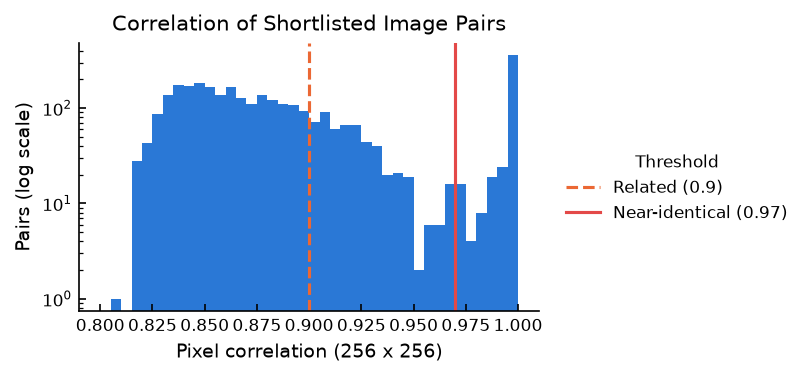

In [7]:
files_with_copies = index[index["md5"].duplicated(keep=False)].groupby("md5")["path"]
assert all(len({path.read_bytes() for path in paths}) == 1 for _, paths in files_with_copies)  # exact copies

pairs = find_similar_pairs(index)
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 2.4))
ax.hist(pairs["correlation"], bins=np.arange(0.8, 1.0001, 0.005), color="#2a78d6")
ax.set_yscale("log")
ax.axvline(RELATED_CORRELATION, color="#eb6834", linestyle="--", label=f"Related ({RELATED_CORRELATION})")
ax.axvline(
    NEAR_IDENTICAL_CORRELATION, color="#e34948", label=f"Near-identical ({NEAR_IDENTICAL_CORRELATION})"
)
ax.set_xlabel("Pixel correlation (256 x 256)")
ax.set_ylabel("Pairs (log scale)")
ax.set_title("Correlation of Shortlisted Image Pairs")
fig.legend(loc="outside right center", title="Threshold")
save_figure(fig, "04_pair_correlation")

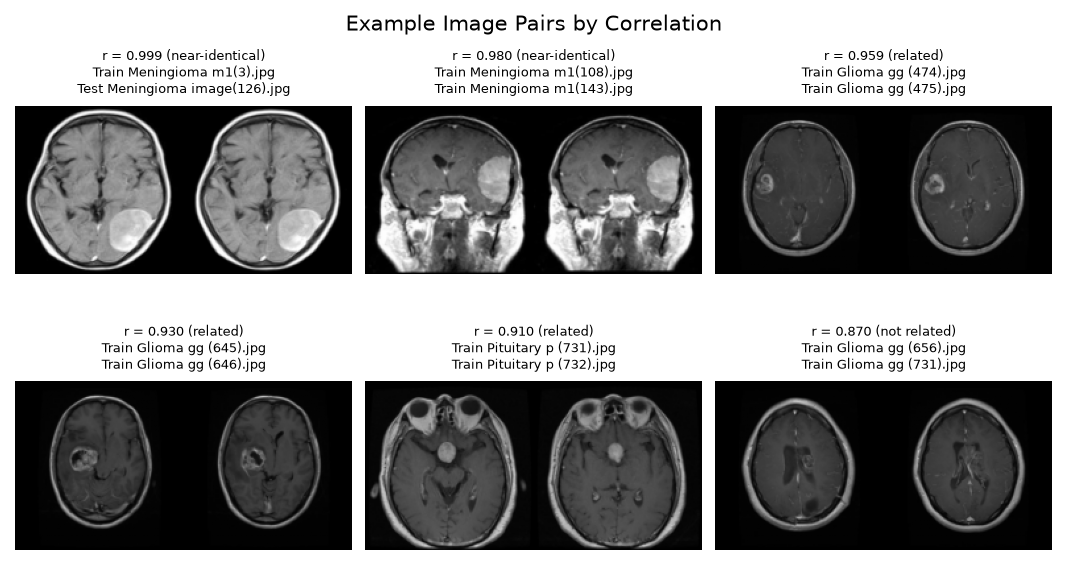

In [8]:
examples = [
    (pairs["correlation"] - target).abs().idxmin() for target in [0.999, 0.98, 0.96, 0.93, 0.91, 0.87]
]
fig, axes = plt.subplots(2, 3, figsize=(FIGURE_WIDTH, 3.9))
for ax, (a, b, mirrored, correlation) in zip(
    axes.flat, pairs.loc[examples].itertuples(index=False), strict=True
):
    left, right = small[a][:, ::-1] if mirrored else small[a], small[b]
    ax.imshow(np.hstack([left, right]), cmap="gray", vmin=0, vmax=255)
    ax.set_axis_off()
    if correlation >= NEAR_IDENTICAL_CORRELATION:
        kind = "near-identical"
    elif correlation >= RELATED_CORRELATION:
        kind = "related"
    else:
        kind = "not related"
    names = [
        f"{'Train' if index.at[k, 'split'] == 'training' else 'Test'} {CLASS_LABELS[index.at[k, 'label']]} "
        f"{index.at[k, 'path'].name}"
        for k in (a, b)
    ]
    ax.set_title(f"r = {correlation:.3f} ({kind})" + chr(10) + chr(10).join(names), fontsize=6)
fig.suptitle("Example Image Pairs by Correlation")
save_figure(fig, "04_pair_examples")

In [9]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(index), size=300, replace=False)
vectors = standardise(small)
correlation = vectors[sample] @ vectors.T
correlation[np.arange(len(sample)), sample] = 0  # ignore each image with itself
rows, others = np.nonzero(correlation >= 0.95)
brute_force = {tuple(sorted(pair)) for pair in zip(sample[rows].tolist(), others.tolist(), strict=True)}
assert brute_force <= set(zip(pairs["a"].tolist(), pairs["b"].tolist(), strict=True))  # shortlist misses none

index = flag_duplicates(index, pairs)
training = index[index["split"] == "training"]
testing = index[index["split"] == "testing"]
duplicates = pd.DataFrame(
    {
        "Training images": training.groupby("label").size(),
        "Related to a test image (dropped)": training.groupby("label")["leak"].sum(),
        "Near-identical within training (dropped)": training.groupby("label")["near_identical"].sum(),
        "Training kept": training.groupby("label")["keep"].sum(),
        "Test images": testing.groupby("label").size(),
        "Near-identical within testing (kept)": testing["near_identical_group"]
        .duplicated()
        .groupby(testing["label"])
        .sum(),
    }
).rename(index=CLASS_LABELS)
duplicates.loc["Total"] = duplicates.sum()
shown = duplicates.astype(object)
for column, total in [
    ("Related to a test image (dropped)", "Training images"),
    ("Near-identical within training (dropped)", "Training images"),
    ("Training kept", "Training images"),
    ("Near-identical within testing (kept)", "Test images"),
]:
    shown[column] = [
        f"{n:,} ({n / t:.0%})" for n, t in zip(duplicates[column], duplicates[total], strict=True)
    ]
shown.rename_axis("Class")

,Training images,Related to a test image (dropped),Near-identical within training (dropped),Training kept,Test images,Near-identical within testing (kept)
Class,,,,,,
Glioma,826,21 (3%),8 (1%),797 (96%),100,17 (17%)
Meningioma,822,116 (14%),3 (0%),703 (86%),115,14 (12%)
No Tumour,395,113 (29%),56 (14%),226 (57%),105,30 (29%)
Pituitary,827,14 (2%),17 (2%),796 (96%),74,40 (54%)
Total,2870,264 (9%),84 (3%),"2,522 (88%)",394,101 (26%)


Label conflicts: near-identical groups whose images carry different class labels.

In [10]:
conflicts = index[index.groupby("near_identical_group")["label"].transform("nunique") > 1]
pd.DataFrame(
    {
        "Near-identical group": conflicts["near_identical_group"].rank(method="dense").astype(int),
        "Split": conflicts["split"],
        "Class label": conflicts["label"].map(CLASS_LABELS),
        "File": conflicts["path"].map(lambda p: p.name),
    }
).sort_values(["Near-identical group", "Split", "Class label"]).style.hide(axis="index")

Near-identical group,Split,Class label,File
1,testing,Glioma,image(48).jpg
1,testing,Meningioma,image(2).jpg
1,testing,Meningioma,image(58).jpg
1,testing,Meningioma,image(82).jpg
1,training,Meningioma,m1(111).jpg
1,training,Meningioma,m1(168).jpg
1,training,Meningioma,m1(192).jpg
2,testing,Glioma,image(2).jpg
2,testing,Meningioma,image(13).jpg
2,training,Meningioma,m1(123).jpg


Repeats within testing (one row per near-identical group; all images are kept):

In [11]:
repeated = testing[testing["near_identical_group"].duplicated(keep=False)]
repeat_list = repeated.groupby("near_identical_group").agg(
    Class=("label", lambda labels: " / ".join(sorted({CLASS_LABELS[label] for label in labels}))),
    Images=("path", "size"),
    Files=("path", lambda paths: ", ".join(sorted(p.name for p in paths))),
)
assert repeat_list["Images"].sum() - len(repeat_list) == testing["near_identical_group"].duplicated().sum()
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(repeat_list.sort_values(["Class", "Images"], ascending=[True, False]).style.hide(axis="index"))

Class,Images,Files
Glioma,3,"image(11).jpg, image(12).jpg, image(90).jpg"
Glioma,3,"image(28).jpg, image(29).jpg, image(79).jpg"
Glioma,3,"image(52).jpg, image(98).jpg, image(99).jpg"
Glioma,2,"image(64).jpg, image(65).jpg"
Glioma,2,"image(70).jpg, image(71).jpg"
Glioma,2,"image(1).jpg, image.jpg"
Glioma,2,"image(21).jpg, image(95).jpg"
Glioma,2,"image(26).jpg, image(97).jpg"
Glioma,2,"image(3).jpg, image(6).jpg"
Glioma,2,"image(30).jpg, image(84).jpg"


<a id="sec-samples"></a>

## 7. Sample images

**Classes** (Louis et al., 2021):

| Class | What it is | Typical location |
|---|---|---|
| Glioma | Tumour of the glial (supporting) cells of the brain | Grows within the brain tissue |
| Meningioma | Tumour of the meninges, the membranes that cover the brain | Against the skull, pressing on the brain from outside |
| Pituitary | Tumour of the pituitary gland (pituitary adenoma) | Base of the brain, below its centre |
| No Tumour | Scan without a tumour | - |

These typical locations are what the explanations in [notebook 06](06_lrp.ipynb) and [notebook 07](07_gradcam.ipynb) are checked against.

**Views:**

- **Axial:** horizontal slice, seen from below.
- **Coronal:** vertical slice, seen from the front.
- **Sagittal:** vertical slice, seen from the side.

**MRI sequences** (Bitar et al., 2006):

- **T1-weighted:** fluid dark; white matter brighter than grey matter; shows anatomy.
- **T1-weighted with contrast:** a contrast agent is injected; tumours that leak it light up bright.
- **T2-weighted:** fluid bright, so the fluid-filled ventricles look white.
- **FLAIR:** like T2, but the fluid signal is suppressed, so the ventricles look dark.

**Manual observation.** The dataset has no view or sequence labels, and the JPEG files keep no scanner metadata, so views and sequences were judged visually by the author, who is not a radiologist; the labels are not clinically validated. Contrast was judged from a bright tumour or bright blood vessels and cannot be confirmed without the scanner record.

- **Views:** all four classes mix axial, coronal and sagittal views, so the model must recognise each class across views.
- **Sequences:** 24 training images per class were drawn with `seed=2021` from the images left after the exact-copy check (the draw was made before the near-copy check of [Section 6](#sec-duplicates)); labels are in `data/brain_mri_manual_labels.csv`. Nearly all tumour images look like T1 with contrast, while No Tumour images are mostly unenhanced T1 and T2, with a few FLAIR.
- **Implication:** the sequence is a cue that differs between classes but is not the tumour, a possible shortcut like size and brightness ([Section 5](#sec-sizes)).

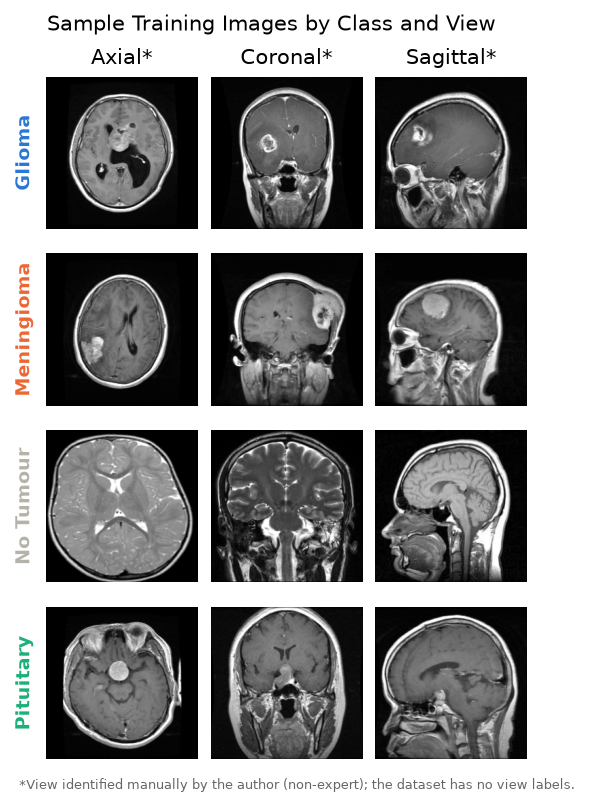

In [12]:
view_samples = {  # one kept training image per class and view, view identified manually
    "glioma_tumor": ["gg (551).jpg", "gg (307).jpg", "gg (52).jpg"],
    "meningioma_tumor": ["m (108).jpg", "m2 (93).jpg", "m3 (181).jpg"],
    "no_tumor": ["image (33).jpg", "image(211).jpg", "image(142).jpg"],
    "pituitary_tumor": ["p (794).jpg", "p (79).jpg", "p (317).jpg"],
}
kept = training[training["keep"]]

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(FIGURE_WIDTH * 0.5, FIGURE_WIDTH * 0.5 * 4 / 3 + 0.6))
for row, label in zip(axes, CLASSES, strict=True):
    paths = kept.loc[kept["label"] == label, "path"]
    paths = paths.set_axis(paths.map(lambda p: p.name))[view_samples[label]]
    for ax, image in zip(row, normalise(load_images(paths)), strict=True):
        show_image(ax, image)
    row[0].text(
        -0.08,
        0.5,
        CLASS_LABELS[label],
        transform=row[0].transAxes,
        rotation=90,
        ha="right",
        va="center",
        fontsize=9,
        color=CLASS_COLORS[label],
        fontweight="bold",
    )
for ax, view in zip(axes[0], ["Axial*", "Coronal*", "Sagittal*"], strict=True):
    ax.set_title(view)
fig.suptitle("Sample Training Images by Class and View")
fig.supxlabel(
    "*View identified manually by the author (non-expert); the dataset has no view labels.",
    x=0.02,
    ha="left",
    fontsize=6,
    color="0.4",
)
save_figure(fig, "04_samples")

Manually labelled MRI sequences, 24 training images per class (author, non-expert):

In [13]:
manual = pd.read_csv(MANUAL_LABELS_PATH)
names = index["path"].map(lambda p: p.name).rename("file")
labels = pd.concat([index[["split", "label"]], names], axis=1).merge(
    manual, on=["split", "label", "file"], how="left"
)  # one row per image, in index order; empty where not reviewed

exact_checked = training[~training["md5"].isin(testing["md5"]) & ~training["md5"].duplicated()]
rng = np.random.default_rng(SEED)
for label in CLASSES:  # the labelled files are exactly this seeded draw
    paths = exact_checked.loc[exact_checked["label"] == label, "path"].reset_index(drop=True)
    drawn = paths.iloc[rng.choice(len(paths), size=24, replace=False)].map(lambda p: p.name)
    assert set(drawn) == set(manual.loc[manual["sequence"].notna() & (manual["label"] == label), "file"])

sequences = ["T1 with contrast", "T1", "T2", "FLAIR", "Unclear"]
sequence_labels = manual[manual["sequence"].notna()]
tally = pd.crosstab(sequence_labels["label"].map(CLASS_LABELS), sequence_labels["sequence"])
tally.reindex(columns=sequences, fill_value=0).rename_axis(index="Class", columns="Sequence (manual)")

Sequence (manual),T1 with contrast,T1,T2,FLAIR,Unclear
Class,,,,,
Glioma,24,0,0,0,0
Meningioma,22,0,1,1,0
No Tumour,1,11,9,2,1
Pituitary,22,2,0,0,0


<a id="sec-ct"></a>

## 8. CT scans

The dataset is described as MRI, but some images are computed tomography (CT) scans. On CT the skull is the brightest structure and the brain is a flat grey; on MRI the skull is dark.

**How the CT images were found** (every label is the author's visual judgement, not a radiologist's; not clinically validated):

1. Sort all 3,264 images by the share of the head that is pure white (grey level 235 or more), and confirm by eye the clear CT images among the top 48.
2. Use those CT images and the 96 MRI images labelled for sequences ([Section 7](#sec-samples)) as examples.
3. Describe every image by the ImageNet-trained VGG16 features, without fine-tuning (`imagenet_features()`).
4. Fit a logistic regression that separates the CT examples from the MRI examples, and give every image a CT score. The score only orders the images for review; it labels nothing.
5. Review by eye the 300 images with the highest CT score from step 4, then 300 images drawn at random (`seed=2021`) from the remaining 2,964.

**Findings**

- **71 CT images**, all within the top 100 of the ranking: 35 in training, all No Tumour or Meningioma, and 36 in testing, including 3 gliomas. Two more images (one scan stored in both splits) are unclear.
- **No CT among the 300 random images.** If a share $p$ of the remaining images were CT, the chance of drawing none in 300 is $(1-p)^{300}$; this is below 5% once $p$ reaches 1%, so the CT share in the rest is probably below 1% (rule of three, $3/300 = 1\%$; Hanley & Lippman-Hand, 1983).
- **No glioma or pituitary CT image is in training.**

**Implications**

- In training, CT appears only with No Tumour and Meningioma, a further cue that is not the tumour itself.
- The test CT gliomas have no CT training example of their class.
- [Notebook 05](05_vgg16_training.ipynb) reports test results separately for CT and MRI. CT images related to test images are already removed from training ([Section 6](#sec-duplicates)).

In [14]:
head = small > 20
bright_share = ((small >= 235) & head).sum(axis=(1, 2)) / head.sum(axis=(1, 2)).clip(min=1)
top_bright = np.argsort(-bright_share, kind="stable")[:48]
ct_examples = top_bright[labels["modality"].to_numpy()[top_bright] == "CT"]
mri_examples = np.flatnonzero(labels["sequence"].notna())

features = imagenet_features(index["path"])
classifier = LogisticRegression(max_iter=2000, class_weight="balanced").fit(
    features[np.r_[ct_examples, mri_examples]], np.r_[np.ones(len(ct_examples)), np.zeros(len(mri_examples))]
)
ct_rank = np.argsort(-classifier.predict_proba(features)[:, 1], kind="stable")
rest = ct_rank[300:]
random_check = rest[np.random.default_rng(SEED).choice(len(rest), size=300, replace=False)]

reviewed = labels["reviewed_for"].fillna("")
assert reviewed.iloc[ct_rank[:300]].str.contains("top 300").all()
assert reviewed.iloc[random_check].str.contains("random 300").all()
assert not labels.loc[~reviewed.str.contains("modality"), "modality"].isin(["CT", "Unclear"]).any()

review_group = pd.Series(pd.NA, index=index.index, dtype="object")
review_group.iloc[ct_rank[:300]] = np.repeat(["Ranks 1-100", "Ranks 101-200", "Ranks 201-300"], 100)
review_group.iloc[random_check] = "Random 300 of the rest"
outcome = pd.crosstab(review_group.dropna(), labels.loc[review_group.notna(), "modality"])
outcome = outcome.reindex(["Ranks 1-100", "Ranks 101-200", "Ranks 201-300", "Random 300 of the rest"])
outcome.reindex(columns=["CT", "Unclear", "MRI"], fill_value=0).rename_axis(
    index=f"Reviewed images ({len(ct_examples)} CT + {len(mri_examples)} MRI examples)",
    columns="Modality (manual)",
)

Modality (manual),CT,Unclear,MRI
Reviewed images (43 CT + 96 MRI examples),,,
Ranks 1-100,71,2,27
Ranks 101-200,0,0,100
Ranks 201-300,0,0,100
Random 300 of the rest,0,0,300


In [15]:
upper_bound = 1 - 0.05 ** (1 / 300)
pd.DataFrame(
    {
        "CT found": [int((labels["modality"].iloc[random_check] == "CT").sum())],
        "95% upper bound, exact": [f"{upper_bound:.2%}"],
        "95% upper bound, rule of three (3/300)": [f"{3 / 300:.2%}"],
    },
    index=["Random 300 of the rest"],
)

,CT found,"95% upper bound, exact","95% upper bound, rule of three (3/300)"
Random 300 of the rest,0,0.99%,1.00%


In [16]:
index["modality"] = labels["modality"].fillna("MRI (not reviewed)").to_numpy()
modality = pd.crosstab([index["split"], index["label"].map(CLASS_LABELS)], index["modality"])
modality = modality.reindex(columns=["CT", "Unclear", "MRI", "MRI (not reviewed)"], fill_value=0)
modality.reindex(["training", "testing"], level=0).rename_axis(
    index=["Split", "Class"], columns="Modality (manual)"
)

Modality (manual)    CT  Unclear  MRI  MRI (not reviewed)
Split    Class                                           
training Glioma       0        0  130                 696
         Meningioma   5        1  196                 620
         No Tumour   30        0   76                 289
         Pituitary    0        0  100                 727
testing  Glioma       3        0   35                  62
         Meningioma   5        1   43                  66
         No Tumour   28        0   23                  54
         Pituitary    0        0    5                  69

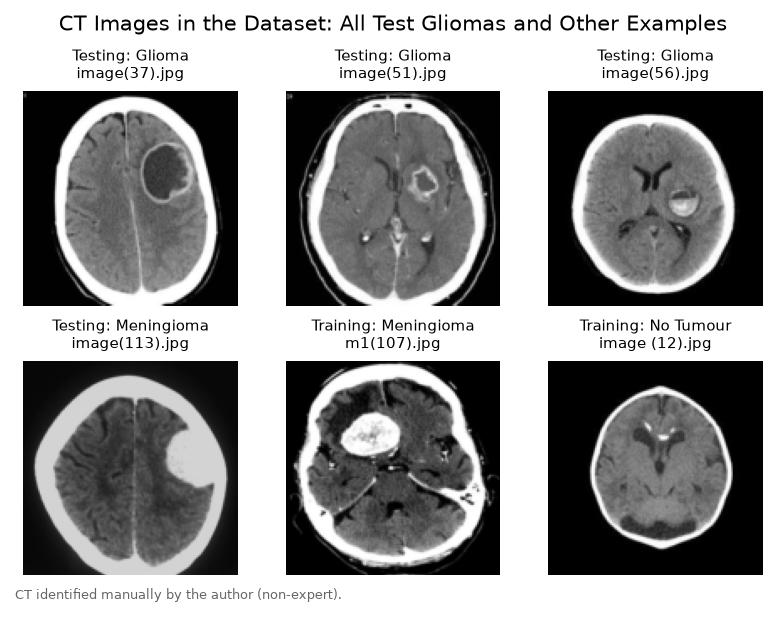

In [17]:
ct = index[index["modality"] == "CT"]
shown_ct = pd.concat(
    [
        ct[(ct["split"] == "testing") & (ct["label"] == "glioma_tumor")],
        ct[(ct["split"] == "testing") & (ct["label"] == "meningioma_tumor")].head(1),
        ct[(ct["split"] == "training") & (ct["label"] == "meningioma_tumor")].head(1),
        ct[(ct["split"] == "training") & (ct["label"] == "no_tumor")].head(1),
    ]
)
fig, axes = plt.subplots(2, 3, figsize=(FIGURE_WIDTH * 0.75, FIGURE_WIDTH * 0.5 + 0.5))
for ax, (k, row) in zip(axes.flat, shown_ct.iterrows(), strict=True):
    ax.imshow(small[k], cmap="gray", vmin=0, vmax=255)
    ax.set_axis_off()
    ax.set_title(
        f"{row['split'].title()}: {CLASS_LABELS[row['label']]}" + chr(10) + row["path"].name, fontsize=7
    )
fig.suptitle("CT Images in the Dataset: All Test Gliomas and Other Examples")
fig.supxlabel(
    "CT identified manually by the author (non-expert).", x=0.02, ha="left", fontsize=6, color="0.4"
)
save_figure(fig, "04_ct_examples")

<a id="sec-subsets"></a>

## 9. Modelling subsets

- **Train / validation:** the kept training images are split about 86 / 14 with `StratifiedGroupKFold` (7 folds, one held out, `seed=2021`), stratified by class. Related images ([Section 6](#sec-duplicates)) stay in the same subset, so neighbouring slices of one scan cannot sit on both sides.
- **Use:** the validation subset picks the training epoch; the test set is used once, for the final evaluation.
- **Reuse:** notebooks [05](05_vgg16_training.ipynb), [06](06_lrp.ipynb) and [07](07_gradcam.ipynb) rebuild the same split from the same functions and seed.

In [18]:
subsets = split_train_validation(index)
table = pd.crosstab(subsets["label"].map(CLASS_LABELS), subsets["subset"])[["train", "validation", "test"]]
table.loc["Total"] = table.sum()
table.rename_axis(index="Class", columns="Subset")

Subset,train,validation,test
Class,,,
Glioma,683,114,100
Meningioma,602,101,115
No Tumour,194,32,105
Pituitary,682,114,74
Total,2161,361,394


<a id="sec-takeaways"></a>

## 10. Key takeaways

1. **Dataset verified** ([Section 2](#sec-download)): all 3,264 images are byte-identical (SHA-256) to the GitHub repository's pinned commit.
2. **Layout ready for `05_lrp.py`** ([Section 3](#sec-layout)): its own data cells load both folders unchanged.
3. **No Tumour is the training minority** ([Section 4](#sec-balance)), and the class proportions differ between training and testing.
4. **Size and brightness track class and split** ([Section 5](#sec-sizes)): expect test tumours to be confused with No Tumour.
5. **Heavy leakage removed** ([Section 6](#sec-duplicates)): 264 training images related to test images and 84 near-identical training images are dropped, leaving 2,522; the test set keeps 101 repeats and 2 label conflicts, disclosed.
6. **Mixed views and sequences** ([Section 7](#sec-samples)): tumour images are nearly all T1 with contrast, No Tumour images mostly T1 and T2 (manual labels, 96 images).
7. **CT scans in an MRI dataset** ([Section 8](#sec-ct)): 71 CT images, in training only No Tumour and Meningioma; the CT share among unreviewed images is probably below 1%.
8. **Final subsets** ([Section 9](#sec-subsets)): train 2,161, validation 361, test 394 images.
9. **Manual labels** (views, sequences, CT, near-copy thresholds) are visual judgements by a non-expert and are not clinically validated.

<a id="sec-references"></a>

## 11. References

Bhuvaji, S., Kadam, A., Bhumkar, P., Dedge, S., & Kanchan, S. (2020). *Brain tumor classification (MRI)* [Data set]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/1183165

Bitar, R., Leung, G., Perng, R., Tadros, S., Moody, A. R., Sarrazin, J., McGregor, C., Christakis, M., Symons, S., Nelson, A., & Roberts, T. P. (2006). MR pulse sequences: What every radiologist wants to know but is afraid to ask. *RadioGraphics, 26*(2), 513-537. https://doi.org/10.1148/rg.262055063

deepfindr. (2021). *xai-series* [Computer software]. GitHub. https://github.com/deepfindr/xai-series

Hanley, J. A., & Lippman-Hand, A. (1983). If nothing goes wrong, is everything all right? Interpreting zero numerators. *JAMA, 249*(13), 1743-1745. https://doi.org/10.1001/jama.1983.03330370053031

Kerby, D. S. (2014). The simple difference formula: An approach to teaching nonparametric correlation. *Comprehensive Psychology, 3*, Article 11.IT.3.1. https://doi.org/10.2466/11.IT.3.1

Louis, D. N., Perry, A., Wesseling, P., Brat, D. J., Cree, I. A., Figarella-Branger, D., Hawkins, C., Ng, H. K., Pfister, S. M., Reifenberger, G., Soffietti, R., von Deimling, A., & Ellison, D. W. (2021). The 2021 WHO classification of tumors of the central nervous system: A summary. *Neuro-Oncology, 23*(8), 1231-1251. https://doi.org/10.1093/neuonc/noab106

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50-60. https://doi.org/10.1214/aoms/1177730491